# Part 1 — recorded teleradiology arrivals

**Forecast origin: October 1, 2026; horizon: 744 source-clock hours.**
Only the supplied synthetic data is used. These are recorded arrivals, not
verified underlying demand. Timezone is unspecified. No LLM produces these forecasts.
This notebook reads saved experiment results and never trains or selects models.


In [1]:
import json
from io import BytesIO
from pathlib import Path

import matplotlib
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()


def show_chart(figure):
    figure.tight_layout()
    with BytesIO() as image_data:
        figure.savefig(image_data, format="png")
        display(Image(data=image_data.getvalue()))
    plt.close(figure)


selection = json.loads((ROOT / "artifacts/selection.json").read_text())
metadata = json.loads((ROOT / "artifacts/forecast_metadata.json").read_text())
name = selection["selected_candidate"]
dev = pd.read_csv(ROOT / "artifacts/development/metrics.csv")
final = pd.read_csv(ROOT / "artifacts/final/metrics.csv")
hourly = pd.read_csv(ROOT / "forecast.csv", parse_dates=["hour_start"]).set_index(
    "hour_start"
)
daily = pd.read_csv(
    ROOT / "artifacts/daily_forecast.csv", parse_dates=["date"]
).set_index("date")
backtest = pd.read_csv(
    ROOT / f"artifacts/final/2026-09-01_{name}_hourly.csv", parse_dates=["hour_start"]
).set_index("hour_start")
backtest_daily = pd.read_csv(
    ROOT / f"artifacts/final/2026-09-01_{name}_daily.csv", parse_dates=["date"]
).set_index("date")
print("Selected before September:", name)
print("October daily point definition:", metadata["daily_point_estimate"])

Selected before September: quantile_filtered
October daily point definition: sum_of_hourly_medians


## Data and input validity

Count study rows per hour on a complete June–September grid (2,928 hours).
No-row hours become zero recorded arrivals. Near-empty days are identified
within each training fold using less than 10% of its weekday median.
Only training rows are optionally excluded; all validation actuals remain.
The repeated `day_total_studies` field is a retrospective consistency check,
never a future feature, label replacement, or missing-hour repair.

| Feature | Why available at origin |
|---|---|
| Hour, weekday, weekend | Known future calendar |
| Hour sine/cosine, weekday sine/cosine | Deterministic encodings of that calendar |
| Days since June 1 | Known elapsed calendar days |

There are no future actual lags, unknown holiday locations, or study-level
attributes in the predictors. Predict the whole horizon directly.


exploration_cutoff_exclusive                                          2026-09-01 00:00:00
rows                                                                               127043
hours                                                                                2208
empty_hours                                                                           668
near_empty_days                                                  [2026-07-08, 2026-07-09]
arrivals_by_stored_hour                 {'0': 0, '1': 1275, '2': 5126, '3': 11447, '4'...
days_with_inconsistent_source_totals                                                    0
days_source_total_differs_from_rows                                                     0
Name: June–August diagnostics, dtype: object

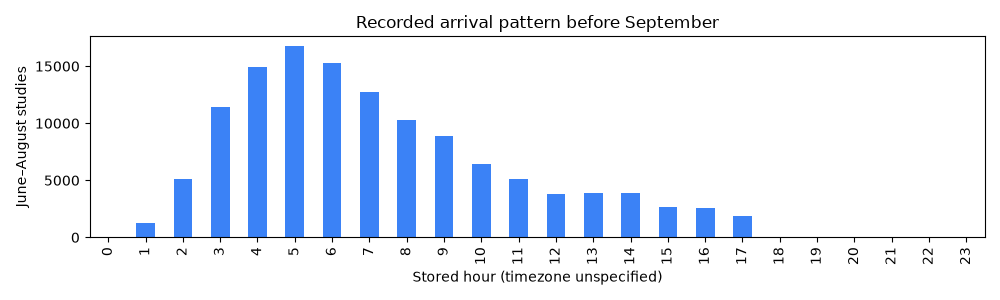

In [2]:
quality = json.loads((ROOT / "artifacts/development/data_quality.json").read_text())
display(pd.Series(quality, name="June–August diagnostics"))
fig, ax = plt.subplots(figsize=(10, 3))
profile = pd.Series(quality["arrivals_by_stored_hour"], dtype=float)
profile.index = profile.index.astype(int)
profile.sort_index().plot.bar(ax=ax, color="#3b82f6")
ax.set(
    title="Recorded arrival pattern before September",
    xlabel="Stored hour (timezone unspecified)",
    ylabel="June–August studies",
)
show_chart(fig)

## Methods and evaluation protocol

Seasonal naive repeats the final 168 observed hours. Histogram gradient boosting
uses Poisson loss for the point model and three separate quantile losses for
p10/p50/p90. Each learned family has raw and sparse-day-filtered variants.
Parameters are fixed at 200 iterations, learning rate 0.05, 15 leaves, minimum
20 samples per leaf, L2=1, seed=42, and no automatic early-stopping split.

Histogram gradient boosting learns nonlinear hour/weekday interactions from the
small tabular calendar dataset without feature scaling and runs on a CPU. One
installed estimator supports both count-oriented Poisson and quantile losses.
Direct quantile regression learns asymmetric, time-varying hourly ranges rather
than adding a fixed band to a point forecast.

Development origins are July 7, July 21, and August 4, with 28-day horizons.
Selection minimizes mean development hourly WAPE, then daily WAPE, then simplicity.
September 1–30 is evaluated only after committing the selection and modelling code.
All five candidates are reported; the September winner cannot change submission selection.

WAPE = sum absolute errors / sum actuals; bias = sum(forecast − actual) / sum actuals.
Total error is signed, forecast minus actual. Percentages with zero actual totals
are undefined. Last-seven-day metrics use 168 hours independently.


In [3]:
columns = [
    "origin",
    "candidate",
    "scope",
    "hourly_wape",
    "daily_wape",
    "bias",
    "actual_total",
    "forecast_total",
    "total_error",
    "absolute_total_error",
    "absolute_total_error_fraction",
    "coverage",
    "mean_interval_width",
    "daily_coverage",
    "quantile_crossing_rate",
    "pinball_10",
    "pinball_50",
    "pinball_90",
]
print("ALL DEVELOPMENT RESULTS — fractions, not percentages")
display(dev[columns])
print("Selection ranking (mean development full-window errors)")
display(pd.read_csv(ROOT / "artifacts/development/ranking.csv"))
print("FROZEN SEPTEMBER RESULTS — fractions, not percentages")
display(final[columns])

ALL DEVELOPMENT RESULTS — fractions, not percentages


,origin,candidate,scope,hourly_wape,daily_wape,bias,actual_total,forecast_total,total_error,absolute_total_error,absolute_total_error_fraction,coverage,mean_interval_width,daily_coverage,quantile_crossing_rate,pinball_10,pinball_50,pinball_90
0,2026-07-07,seasonal_naive,all,0.271674,0.227457,0.152527,34512.0,39776.000000,5264.000000,5264.000000,0.152527,0.833333,36.732143,0.821429,0.000000,NaN,NaN,NaN
1,2026-07-07,seasonal_naive,last_7_days,0.139946,0.098357,0.033895,9618.0,9944.000000,326.000000,326.000000,0.033895,0.916667,36.732143,1.000000,0.000000,NaN,NaN,NaN
2,2026-07-07,poisson_raw,all,0.263588,0.234352,0.119518,34512.0,38636.815357,4124.815357,4124.815357,0.119518,0.812500,32.897562,0.785714,0.000000,NaN,NaN,NaN
3,2026-07-07,poisson_raw,last_7_days,0.138868,0.115982,0.004284,9618.0,9659.203839,41.203839,41.203839,0.004284,0.928571,32.897562,1.000000,0.000000,NaN,NaN,NaN
4,2026-07-07,poisson_filtered,all,0.263588,0.234352,0.119518,34512.0,38636.815357,4124.815357,4124.815357,0.119518,0.812500,32.897562,0.785714,0.000000,NaN,NaN,NaN
5,2026-07-07,poisson_filtered,last_7_days,0.138868,0.115982,0.004284,9618.0,9659.203839,41.203839,41.203839,0.004284,0.928571,32.897562,1.000000,0.000000,NaN,NaN,NaN
6,2026-07-07,quantile_raw,all,0.254834,0.222846,0.130935,34512.0,39030.814966,4518.814966,4518.814966,0.130935,0.836310,68.565889,0.714286,0.029762,5.135714,6.543772,3.151317
7,2026-07-07,quantile_raw,last_7_days,0.125299,0.098551,0.014525,9618.0,9757.703742,139.703742,139.703742,0.014525,0.785714,68.565889,1.000000,0.029762,5.725000,3.586690,2.440875
8,2026-07-07,quantile_filtered,all,0.254834,0.222846,0.130935,34512.0,39030.814966,4518.814966,4518.814966,0.130935,0.836310,68.565889,0.714286,0.029762,5.135714,6.543772,3.151317
9,2026-07-07,quantile_filtered,last_7_days,0.125299,0.098551,0.014525,9618.0,9757.703742,139.703742,139.703742,0.014525,0.785714,68.565889,1.000000,0.029762,5.725000,3.586690,2.440875


Selection ranking (mean development full-window errors)


,candidate,hourly_wape,daily_wape,simplicity
0,quantile_filtered,0.199452,0.170900,4
1,quantile_raw,0.203370,0.174808,3
2,poisson_filtered,0.209839,0.175747,2
3,poisson_raw,0.229546,0.201750,1
4,seasonal_naive,0.241072,0.199645,0


FROZEN SEPTEMBER RESULTS — fractions, not percentages


,origin,candidate,scope,hourly_wape,daily_wape,bias,actual_total,forecast_total,total_error,absolute_total_error,absolute_total_error_fraction,coverage,mean_interval_width,daily_coverage,quantile_crossing_rate,pinball_10,pinball_50,pinball_90
0,2026-09-01,seasonal_naive,all,0.191620,0.154440,0.032487,43033.0,44431.000000,1398.000000,1398.000000,0.032487,0.862500,38.827778,0.800000,0.0,NaN,NaN,NaN
1,2026-09-01,seasonal_naive,last_7_days,0.193211,0.154788,0.033944,10046.0,10387.000000,341.000000,341.000000,0.033944,0.863095,38.827381,0.714286,0.0,NaN,NaN,NaN
2,2026-09-01,poisson_raw,all,0.177839,0.155945,0.101005,43033.0,47379.541377,4346.541377,4346.541377,0.101005,0.879167,34.557190,0.933333,0.0,NaN,NaN,NaN
3,2026-09-01,poisson_raw,last_7_days,0.170106,0.158663,0.100107,10046.0,11051.674114,1005.674114,1005.674114,0.100107,0.880952,34.557190,1.000000,0.0,NaN,NaN,NaN
4,2026-09-01,poisson_filtered,all,0.177803,0.155174,0.108485,43033.0,47701.429443,4668.429443,4668.429443,0.108485,0.879167,35.091915,0.933333,0.0,NaN,NaN,NaN
5,2026-09-01,poisson_filtered,last_7_days,0.168666,0.154810,0.107921,10046.0,11130.173976,1084.173976,1084.173976,0.107921,0.898810,35.091915,1.000000,0.0,NaN,NaN,NaN
6,2026-09-01,quantile_raw,all,0.157135,0.128904,0.051148,43033.0,45234.072793,2201.072793,2201.072793,0.051148,0.904167,72.098900,0.666667,0.0,5.976806,4.695823,2.397260
7,2026-09-01,quantile_raw,last_7_days,0.149622,0.122004,0.049899,10046.0,10547.284313,501.284313,501.284313,0.049899,0.928571,72.117033,0.571429,0.0,5.979762,4.473518,2.380131
8,2026-09-01,quantile_filtered,all,0.158491,0.131238,0.045699,43033.0,44999.564550,1966.564550,1966.564550,0.045699,0.912500,72.065688,0.766667,0.0,5.976806,4.736346,2.367488
9,2026-09-01,quantile_filtered,last_7_days,0.153153,0.124034,0.045159,10046.0,10499.662554,453.662554,453.662554,0.045159,0.928571,72.063872,0.714286,0.0,5.979762,4.579105,2.352416


## Uncertainty and September errors

Hourly quantile bounds are learned directly. Nonnegative sorting repairs crossing
quantiles before scoring/export; crossing rates above refer to the original values.
The point model and baseline use hour-conditioned residual percentiles from three
prior seven-day forecasts, each fit only on earlier history.

Daily ranges use percentiles of **complete-day residuals** from those 21 prior days,
added to daily point totals. They preserve within-day error aggregation and are
not sums of hourly quantiles. Bands are clipped/bracketed to contain nonnegative
point forecasts. Coverage is measured rather than asserted to be 80%.


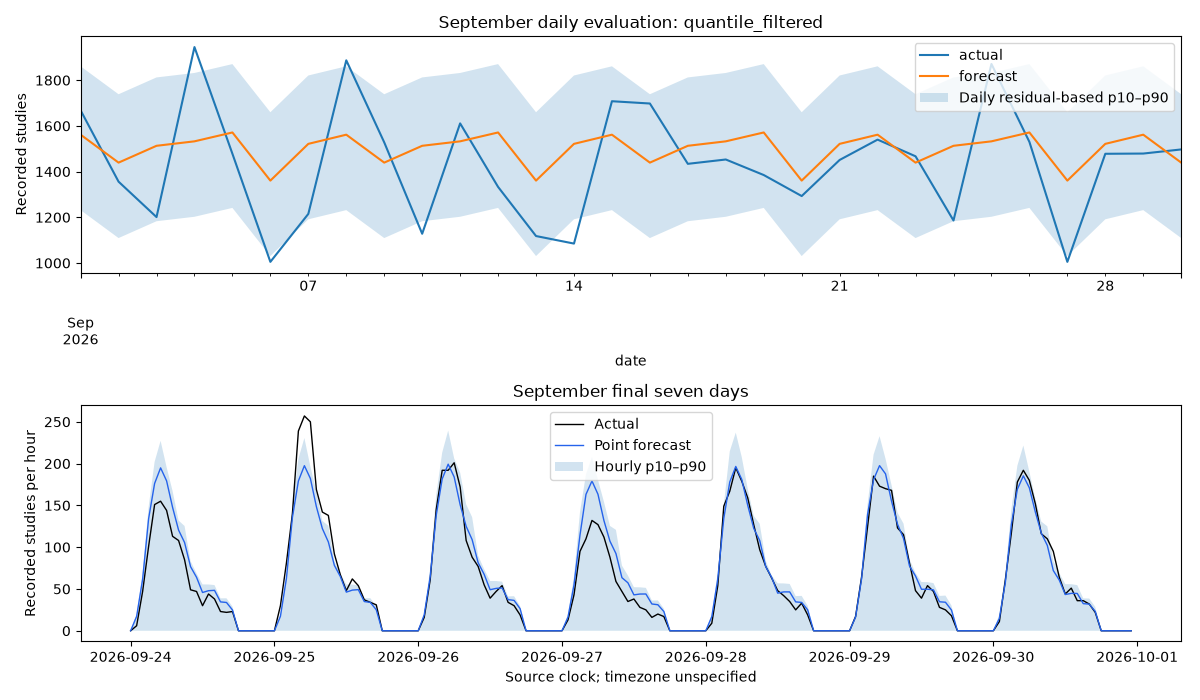

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
backtest_daily[["actual", "forecast"]].plot(ax=axes[0])
axes[0].fill_between(
    backtest_daily.index,
    backtest_daily.p10,
    backtest_daily.p90,
    alpha=0.2,
    label="Daily residual-based p10–p90",
)
axes[0].set(title=f"September daily evaluation: {name}", ylabel="Recorded studies")
axes[0].legend()
week = backtest.loc["2026-09-24":"2026-09-30"]
axes[1].plot(week.index, week.actual, label="Actual", color="black", linewidth=1)
axes[1].plot(
    week.index, week.forecast, label="Point forecast", color="#2563eb", linewidth=1
)
axes[1].fill_between(week.index, week.p10, week.p90, alpha=0.2, label="Hourly p10–p90")
axes[1].set(
    title="September final seven days",
    ylabel="Recorded studies per hour",
    xlabel="Source clock; timezone unspecified",
)
axes[1].legend()
show_chart(fig)

## October operations forecast

All available history through September 30 is used to refit the frozen selected
method. Display daily point totals and ranges for staffing discussions; these
are recorded-arrival forecasts. If p50 is selected, the daily point is a sum of
hourly medians, not an expected value or necessarily a daily median.


October point total: 43,974.8


,forecast,p10,p90
date,,,
2026-10-01,1353.2,1102.6,1499.5
2026-10-02,1535.1,1284.5,1681.4
2026-10-03,1428.2,1177.6,1574.5
2026-10-04,1120.8,870.2,1267.1
2026-10-05,1443.9,1193.3,1590.2
2026-10-06,1552.6,1302.0,1698.9
2026-10-07,1480.8,1230.2,1627.1
2026-10-08,1353.2,1102.6,1499.5
2026-10-09,1535.1,1284.5,1681.4


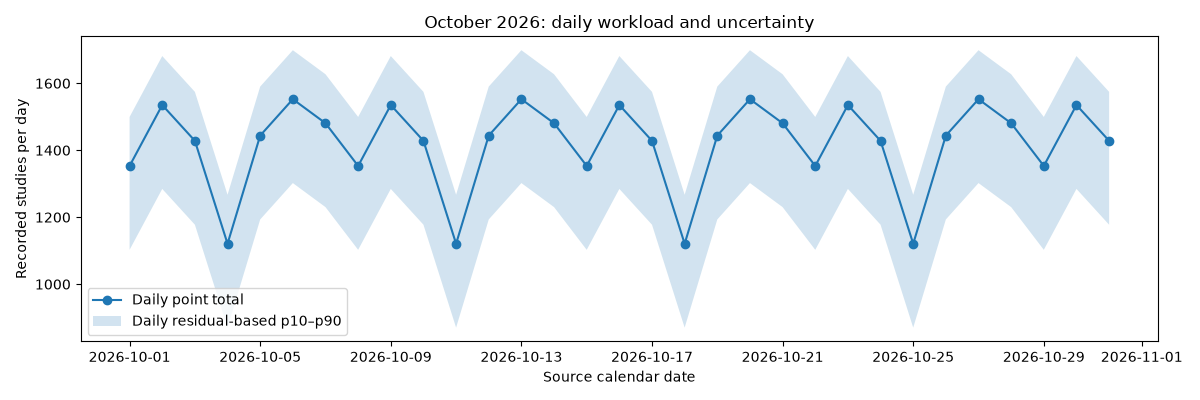

Ten busiest forecast dates/hours (source clock)


,forecast,p10,p90
hour_start,,,
2026-10-06 05:00:00,199.7,0.0,231.0
2026-10-13 05:00:00,199.7,0.0,231.0
2026-10-20 05:00:00,199.7,0.0,231.0
2026-10-27 05:00:00,199.7,0.0,231.0
2026-10-02 05:00:00,196.9,0.0,242.0
2026-10-09 05:00:00,196.9,0.0,242.0
2026-10-16 05:00:00,196.9,0.0,242.0
2026-10-23 05:00:00,196.9,0.0,242.0
2026-10-30 05:00:00,196.9,0.0,242.0


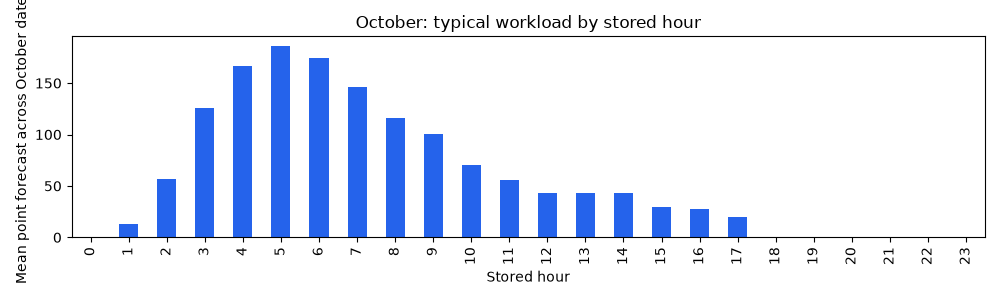

In [5]:
print(f"October point total: {hourly.forecast.sum():,.1f}")
display(daily.round(1))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.forecast, marker="o", label="Daily point total")
ax.fill_between(
    daily.index, daily.p10, daily.p90, alpha=0.2, label="Daily residual-based p10–p90"
)
ax.set(
    title="October 2026: daily workload and uncertainty",
    xlabel="Source calendar date",
    ylabel="Recorded studies per day",
)
ax.legend()
show_chart(fig)
print("Ten busiest forecast dates/hours (source clock)")
display(hourly.nlargest(10, "forecast").round(1))
fig, ax = plt.subplots(figsize=(10, 3))
hourly.forecast.groupby(hourly.index.hour).mean().plot.bar(ax=ax, color="#2563eb")
ax.set(
    title="October: typical workload by stored hour",
    xlabel="Stored hour",
    ylabel="Mean point forecast across October dates",
)
show_chart(fig)

## Drawbacks and limitations

The submitted method was frozen as **quantile_filtered** using development windows only.
September is an evaluation result, not a reason to change that selection.

1. **Recorded arrivals are not established demand.** In June–August there are no
   rows at stored hour 00:00 or 18:00–23:00. July 8 and 9 contain only 36 and 1
   studies. We preserve zero recorded counts and do not infer true closures,
   outages, timezone corrections, or unobserved patients. Future capture changes
   could invalidate the learned clock pattern.
2. **Unusual-day treatment matters.** Mean development hourly WAPE is
   20.34% for raw quantile training and
   19.95% with the specified
   near-empty-day exclusion. Validation counts are never removed. Excluding
   plausible capture failures can also remove genuinely low-demand days.
   On September, raw quantile training has 15.71%
   hourly WAPE versus 15.85% for the frozen filtered choice;
   this holdout difference does not change the previously selected method.
3. **Long-horizon performance is measured, not assumed.** September hourly WAPE
   is 15.85% overall and 15.32% in the
   last seven days; bias is 4.57% and 4.52%.
   The three development windows overlap, so they are not independent trials.
4. **An 80% interval is a target, not a guarantee.** September hourly coverage is
   91.25% overall and 92.86% in the final week.
   Coverage on hours with positive recorded arrivals is 87.65%;
   predictable zero hours can make overall coverage look stronger. Daily coverage
   is 76.67% overall and 71.43% in
   the final week. Only 21 complete prior days calibrate daily ranges, using
   seven-day horizons rather than a full month. No post-September recalibration
   or widening is performed to improve the reported holdout.
5. **The feature set has limited information.** Trees can fit historical level
   changes but cannot extrapolate a continuing growth trend beyond training.
   Four months cannot establish annual seasonality or October-specific holidays.
   No future hospital staffing, onboarding, hospital volumes, or outages are
   known. Hourly quantiles are marginal estimates, not joint sample paths.
   A sum of hourly medians is a daily point forecast, not a mathematical
   expectation or necessarily the daily median.
6. **Errors are concentrated.** The largest September daily absolute errors are:

- 2026-09-14: 1,085 recorded studies, 1,521.4 forecast (+436.4); daily range 1,191.3–1,820.6.
- 2026-09-04: 1,945 recorded studies, 1,532.5 forecast (-412.5); daily range 1,202.3–1,831.7.
- 2026-09-10: 1,128 recorded studies, 1,513.0 forecast (+385.0); daily range 1,182.8–1,812.2.

   The largest hourly MAEs by stored hour are 04:00 (27.9 studies MAE), 05:00 (24.1 studies MAE), 06:00 (22.5 studies MAE).

Next steps would be a documented timezone, source-system completeness and outage
logs, more historical months, hospital onboarding schedules, and additional
rolling month-long tests of calibration. These data were not invented for this
submission. October actuals are unavailable; no October accuracy is claimed.


## Reproducibility and handoff

`forecast.csv` is the 744-row submission. API endpoints serve this same saved
forecast and the separately calibrated daily artifact. The permanent pytest
suite covers feature values, input validation, origin-safe training/calibration,
forecast contracts, API responses, date filters, and error handling. Tests use
synthetic temporary artifacts and do not overwrite submitted forecasts.

Run the service with `docker compose up --build` and the tests with
`docker compose run --build --rm tests`. The test service is profile-isolated
from normal API startup; notebook tooling is excluded from the service image.
See README for local testing and pipeline stage commands. Charts are embedded
in this notebook. The original 45-test run is historical; current verification
is recorded in README.
The selection, checksums, and pre-September commit are recorded under `artifacts/`.
AI coding assistance and concrete corrections are disclosed in `AI_USE_LOG.md`.
Part 1 was committed before Part 2. The completed Part 2 sections below report the LLM hybrid comparison and validated explanation demonstrations from saved results, without new LLM calls.


## LLM hybrid — daily volume and historical hourly allocation

**Exploratory comparison:** September outcomes were known before this method was designed.
Qwen predicts two daily point totals per call. Python allocates each total using historical
weekday/hour volume proportions; these points are not directly predicted hourly medians.
Daily/hourly coherence is enforced by Python, not evidence of LLM arithmetic accuracy.

Three prior seven-day hybrid forecasts supply empirical hourly and daily residual bands.
Daily ranges are calibrated separately, never sums of hourly bounds. Only 21 residuals per
clock hour are available. These ranges have no guaranteed 80% coverage and seven-day
calibration may miss late-month uncertainty. Sparse days remain recorded observations.
Timezone is unspecified. Profiles cannot anticipate new hospitals, holidays or demand shifts.

This is a hybrid deviation from L1: the LLM predicts daily totals rather than direct hourly
10th/50th/90th quantiles. The previous direct experiment and its evidence were deleted at
user request after selecting this approach; they are not presented as retained results.


In [6]:
from pathlib import Path
from io import BytesIO
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from llm_forecasting.reporting import saved_report_data
HYBRID_ROOT = Path.cwd().resolve()
hybrid_report = saved_report_data(HYBRID_ROOT)
display(hybrid_report['comparison'])
display(hybrid_report['diagnostics'])
print(hybrid_report['recommendation'])


,origin,candidate,scope,hours,days,actual_total,forecast_total,hourly_wape,daily_wape,bias,...,daily_coverage,mean_daily_interval_width,quantile_crossing_rate,pinball_10,pinball_50,pinball_90,method_source,stage,run,interval_method
0,2026-07-07,seasonal_naive,all,672,28,34512.0,39776.000000,0.271674,0.227457,0.152527,...,0.821429,716.000000,0.000000,NaN,NaN,NaN,Part 1,development,NaN,NaN
1,2026-07-07,seasonal_naive,last_7_days,168,7,9618.0,9944.000000,0.139946,0.098357,0.033895,...,1.000000,716.000000,0.000000,NaN,NaN,NaN,Part 1,development,NaN,NaN
2,2026-07-07,poisson_raw,all,672,28,34512.0,38636.815357,0.263588,0.234352,0.119518,...,0.785714,688.205573,0.000000,NaN,NaN,NaN,Part 1,development,NaN,NaN
3,2026-07-07,poisson_raw,last_7_days,168,7,9618.0,9659.203839,0.138868,0.115982,0.004284,...,1.000000,688.205573,0.000000,NaN,NaN,NaN,Part 1,development,NaN,NaN
4,2026-07-07,poisson_filtered,all,672,28,34512.0,38636.815357,0.263588,0.234352,0.119518,...,0.785714,688.205573,0.000000,NaN,NaN,NaN,Part 1,development,NaN,NaN
5,2026-07-07,poisson_filtered,last_7_days,168,7,9618.0,9659.203839,0.138868,0.115982,0.004284,...,1.000000,688.205573,0.000000,NaN,NaN,NaN,Part 1,development,NaN,NaN
6,2026-07-07,quantile_raw,all,672,28,34512.0,39030.814966,0.254834,0.222846,0.130935,...,0.714286,543.835799,0.029762,5.135714,6.543772,3.151317,Part 1,development,NaN,NaN
7,2026-07-07,quantile_raw,last_7_days,168,7,9618.0,9757.703742,0.125299,0.098551,0.014525,...,1.000000,543.835799,0.029762,5.725000,3.586690,2.440875,Part 1,development,NaN,NaN
8,2026-07-07,quantile_filtered,all,672,28,34512.0,39030.814966,0.254834,0.222846,0.130935,...,0.714286,543.835799,0.029762,5.135714,6.543772,3.151317,Part 1,development,NaN,NaN
9,2026-07-07,quantile_filtered,last_7_days,168,7,9618.0,9757.703742,0.125299,0.098551,0.014525,...,1.000000,543.835799,0.029762,5.725000,3.586690,2.440875,Part 1,development,NaN,NaN


,origin,run,daily_volume_absolute_error,oracle_daily_volume_hourly_wape,note
0,2026-07-07,1,7832.133333,0.108271,Oracle uses actual daily totals for diagnosis ...
1,2026-07-21,1,5338.457143,0.084975,Oracle uses actual daily totals for diagnosis ...
2,2026-08-04,1,5801.200000,0.087186,Oracle uses actual daily totals for diagnosis ...
3,2026-09-01,1,5295.938462,0.083754,Oracle uses actual daily totals for diagnosis ...
4,2026-09-01,2,5377.769231,0.083754,Oracle uses actual daily totals for diagnosis ...
5,2026-09-01,3,5494.492308,0.083754,Oracle uses actual daily totals for diagnosis ...


Mean September hourly WAPE: selected Part 1 15.85%, LLM hybrid 15.03%. Keep Part 1 as the established operational baseline and use validated LLM explanations; any hybrid promotion requires fresh future evaluation and interval checks. Exploratory: September outcomes were already inspected before designing this hybrid.


development {
  "main": {
    "attempts": 42,
    "received_replies": 42,
    "invalid_replies": 0,
    "invalid_reply_share": 0.0,
    "partial_replies": 0,
    "retry_calls": 0,
    "accepted_daily_values": 84,
    "requested_daily_values": 84,
    "transport_failures": 0,
    "http_failures": 0,
    "interrupted_attempts": 0,
    "mean_call_seconds": 4.5402001945185475,
    "active_request_seconds": 190.688408169779,
    "input_tokens": 52892,
    "output_tokens": 1764,
    "usage_missing_attempts": 0,
    "api_cost_usd": 0.0,
    "cost_excludes": "hardware and electricity"
  },
  "calibration": {
    "attempts": 36,
    "received_replies": 36,
    "invalid_replies": 0,
    "invalid_reply_share": 0.0,
    "partial_replies": 0,
    "retry_calls": 0,
    "accepted_daily_values": 63,
    "requested_daily_values": 63,
    "transport_failures": 0,
    "http_failures": 0,
    "interrupted_attempts": 0,
    "mean_call_seconds": 3.9440417881075214,
    "active_request_seconds": 141.98550437

,origin,run,complete_forecast_seconds,last_invocation_seconds,active_request_seconds
0,2026-07-07,1,89.095820,89.096491,88.962350
1,2026-07-21,1,117.236315,117.321668,117.083242
2,2026-08-04,1,126.932431,126.934956,126.628321


final {
  "main": {
    "attempts": 45,
    "received_replies": 45,
    "invalid_replies": 0,
    "invalid_reply_share": 0.0,
    "partial_replies": 0,
    "retry_calls": 0,
    "accepted_daily_values": 90,
    "requested_daily_values": 90,
    "transport_failures": 0,
    "http_failures": 0,
    "interrupted_attempts": 0,
    "mean_call_seconds": 7.3282538824223185,
    "active_request_seconds": 329.77142470900435,
    "input_tokens": 58590,
    "output_tokens": 2196,
    "usage_missing_attempts": 0,
    "api_cost_usd": 0.0,
    "cost_excludes": "hardware and electricity"
  },
  "calibration": {
    "attempts": 36,
    "received_replies": 36,
    "invalid_replies": 0,
    "invalid_reply_share": 0.0,
    "partial_replies": 0,
    "retry_calls": 0,
    "accepted_daily_values": 63,
    "requested_daily_values": 63,
    "transport_failures": 0,
    "http_failures": 0,
    "interrupted_attempts": 0,
    "mean_call_seconds": 6.651171171284255,
    "active_request_seconds": 239.4421621662331

,origin,run,complete_forecast_seconds,last_invocation_seconds,active_request_seconds
0,2026-09-01,1,190.857261,190.859186,190.136242
1,2026-09-01,2,189.495033,189.496944,188.743063
2,2026-09-01,3,191.260878,191.224176,190.334282


october {
  "main": {
    "attempts": 16,
    "received_replies": 16,
    "invalid_replies": 0,
    "invalid_reply_share": 0.0,
    "partial_replies": 0,
    "retry_calls": 0,
    "accepted_daily_values": 31,
    "requested_daily_values": 31,
    "transport_failures": 0,
    "http_failures": 0,
    "interrupted_attempts": 0,
    "mean_call_seconds": 7.698613663938886,
    "active_request_seconds": 123.17781862302218,
    "input_tokens": 20772,
    "output_tokens": 760,
    "usage_missing_attempts": 0,
    "api_cost_usd": 0.0,
    "cost_excludes": "hardware and electricity"
  },
  "calibration": {
    "attempts": 12,
    "received_replies": 12,
    "invalid_replies": 0,
    "invalid_reply_share": 0.0,
    "partial_replies": 0,
    "retry_calls": 0,
    "accepted_daily_values": 21,
    "requested_daily_values": 21,
    "transport_failures": 0,
    "http_failures": 0,
    "interrupted_attempts": 0,
    "mean_call_seconds": 6.771690753414684,
    "active_request_seconds": 81.2602890409762,

,origin,run,complete_forecast_seconds,last_invocation_seconds,active_request_seconds
0,2026-10-01,1,205.575573,205.576511,204.438108


September repeatability: {
  "monthly_totals": {
    "run1": 41937.769230769234,
    "run2": 41845.93846153846,
    "run3": 41901.123076923075
  },
  "monthly_total_range": 91.8307692307717,
  "pairwise_hourly_mae": [
    {
      "runs": [
        "run1",
        "run2"
      ],
      "mae": 0.12801282051282062
    },
    {
      "runs": [
        "run1",
        "run3"
      ],
      "mae": 0.7408974358974361
    },
    {
      "runs": [
        "run2",
        "run3"
      ],
      "mae": 0.6272008547008548
    }
  ],
  "mean_hourly_std": 0.35107341002050746,
  "max_hourly_std": 6.8072540154463415,
  "daily_total_std": {
    "2026-09-01": 2.2737367544323206e-13,
    "2026-09-02": 0.0,
    "2026-09-03": 41.012193308819754,
    "2026-09-04": 4.895354638983831,
    "2026-09-05": 0.007252377242833413,
    "2026-09-06": 0.014504754485881196,
    "2026-09-07": 0.0,
    "2026-09-08": 0.07252377242940598,
    "2026-09-09": 52.32590180780452,
    "2026-09-10": 39.41516910474387,
    "2026-09-

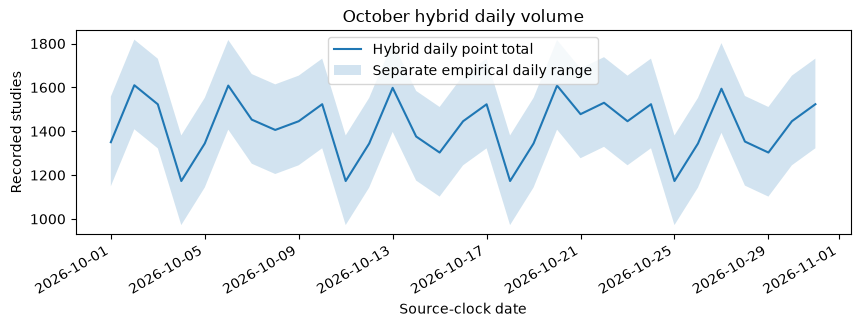

In [7]:
for stage, result in hybrid_report['reliability'].items():
    print(stage, json.dumps({k: {field: value for field, value in result[k].items() if field != 'per_call'} for k in ('main', 'calibration', 'combined')}, indent=2))
    display(pd.DataFrame(result['windows'])[['origin', 'run', 'complete_forecast_seconds', 'last_invocation_seconds', 'active_request_seconds']])
print('September repeatability:', json.dumps(hybrid_report['repeatability'], indent=2))
print('US$0 API charges; hardware and electricity excluded. Timing includes calibration and retries.')
daily = pd.read_csv(HYBRID_ROOT / 'artifacts/llm/october/2026-10-01_run1_daily.csv', parse_dates=['date'])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(daily.date, daily.forecast, label='Hybrid daily point total')
ax.fill_between(daily.date, daily.p10, daily.p90, alpha=0.2, label='Separate empirical daily range')
ax.set(title='October hybrid daily volume', ylabel='Recorded studies', xlabel='Source-clock date')
ax.legend()
fig.autofmt_xdate()
chart_buffer = BytesIO()
fig.savefig(chart_buffer, format='png', bbox_inches='tight')
display(Image(data=chart_buffer.getvalue()))
plt.close(fig)


In [8]:
display(hybrid_report['failure_examples'])
print('These are measured forecast errors, not invalid JSON examples.')
print('Live validated explanation:', hybrid_report['explanations']['live']['explanation'])
print('Simulated outage fallback:', hybrid_report['explanations']['simulated_provider_failure']['explanation'])
print('Coherence is enforced by Python allocation and does not test model arithmetic.')


,date,forecast,p10,p90,llm_total,allocation_error,coherent,actual,run,absolute_error
3,2026-09-04 00:00:00,1351.000000,1275.000000,1654.000000,1351.000000,0.0,True,1945,2,594.000000
24,2026-09-25 00:00:00,1361.400000,1284.400000,1664.400000,1361.400000,0.0,True,1871,1,509.600000
15,2026-09-16 00:00:00,1293.153846,1217.153846,1596.153846,1293.153846,-0.0,True,1698,2,404.846154


These are measured forecast errors, not invalid JSON examples.
Live validated explanation: For 2026-10-01 through 2026-10-31, the forecast totals 43,974.8 recorded studies. The busiest forecast period is 2026-10-01 through 2026-10-07, with 9,914.6 studies. On 2026-10-06, the daily point forecast is 1,552.6 and its range is 1,302.0 to 1,698.9 studies.
Simulated outage fallback: For 2026-10-01 through 2026-10-31, the forecast totals 43,974.8 recorded studies. The busiest forecast period is 2026-10-01 through 2026-10-07, with 9,914.6 studies. On 2026-10-06, the daily point forecast is 1,552.6 and its range is 1,302.0 to 1,698.9 studies.
Coherence is enforced by Python allocation and does not test model arithmetic.
